# Phase 3 — Chaos and Predictability: the Lorenz Systems

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/phase3_chaos.ipynb)

*An overview of the chaotic test problems, moved from somax's tutorial series.*

Before tackling the full fluid models, it is worth meeting deterministic chaos in its smallest form. Edward Lorenz's two systems, a three-variable convection caricature and a $D_x$-variable atmospheric ring, distil the property that makes weather and ocean forecasting hard: a perfectly known, perfectly deterministic system whose trajectories nonetheless become unpredictable because minuscule differences in the initial state grow exponentially {cite}`lorenz1963deterministic,lorenz1996predictability`. sesmax ships both as test problems, and they are the standard test beds for the data-assimilation adapters in `sesmax_core.da`.

**What you'll learn:**

1. How the Lorenz-63 system traces out its butterfly attractor
2. What sensitive dependence on initial conditions looks like quantitatively
3. How the Lorenz-96 ring produces travelling spatiotemporal chaos

### Symbols

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $x(t)$, $y(t)$, $z(t)$ | the Lorenz-63 state variables | $\mathbb{R}$ |
| $\sigma$, $\rho$, $\beta$ | Lorenz-63 parameters | $\mathbb{R}_{>0}$ |
| $\delta(t)$, $\delta_0$ | separation of two trajectories, and its initial value | $\mathbb{R}_{\ge 0}$ |
| $\lambda$ | leading Lyapunov exponent | $\mathbb{R}$ |
| $\tau$, $N_W$, $\delta_w$ | rescaling window, number of windows, and the gap at the end of window $w$ | $\mathbb{R}_{>0}$, count, $\mathbb{R}_{\ge 0}$ |
| $x_k(t)$ | the Lorenz-96 variable at position $k$ | $\mathbb{R}$ |
| $D_x$, $F$ | number of Lorenz-96 variables, and the forcing | count, $\mathbb{R}$ |
| $t$, $N_T$ | time, and the number of saved snapshots | $\mathbb{R}$, count |

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

In [2]:
import diffrax as dfx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

import sesmax_core.testing as sxt

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,diffrax,sesmax_core")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
diffrax    : 0.7.2
sesmax_core: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Lorenz-63: the butterfly attractor

The Lorenz-63 system is three coupled ODEs distilled from Rayleigh–Bénard convection,

$$\frac{\mathrm{d}x}{\mathrm{d}t} = \sigma (y - x)$$ (p3-lorenz63-x)

$$\frac{\mathrm{d}y}{\mathrm{d}t} = x (\rho - z) - y$$ (p3-lorenz63-y)

$$\frac{\mathrm{d}z}{\mathrm{d}t} = x y - \beta z$$ (p3-lorenz63-z)

with the classical parameters $(\sigma, \rho, \beta) = (10, 28, 8/3)$ at which the flow is chaotic {cite}`lorenz1963deterministic`. Trajectories are drawn onto a bounded, fractal strange attractor, the two-lobed butterfly, never repeating yet never escaping. The [Lorenz '63 page](lorenz63_simulation.ipynb) goes further, with gradients and ensembles.

In [4]:
# Shapes: N_T = 5,000 saved snapshots

# today (sesmax_core)
lorenz63 = sxt.Lorenz63.create(sigma=10.0, rho=28.0, beta=8.0 / 3.0)
# x₀ = (1, 1, 1)
initial_state = sxt.L63State(x=jnp.array(1.0), y=jnp.array(1.0), z=jnp.array(1.0))

attractor_times = jnp.arange(0.0, 50.0, 0.01)  # → (N_T,)
# today (sesmax_core, diffrax)
attractor = lorenz63.integrate(  # x, y, z → (N_T,) each
    initial_state,
    t0=0.0,
    t1=50.0,
    dt=0.01,
    saveat=dfx.SaveAt(ts=attractor_times),
    max_steps=20_000,
)
print(f"Lorenz-63 trajectory: {attractor.ys.x.shape[0]} samples")

Lorenz-63 trajectory: 5000 samples


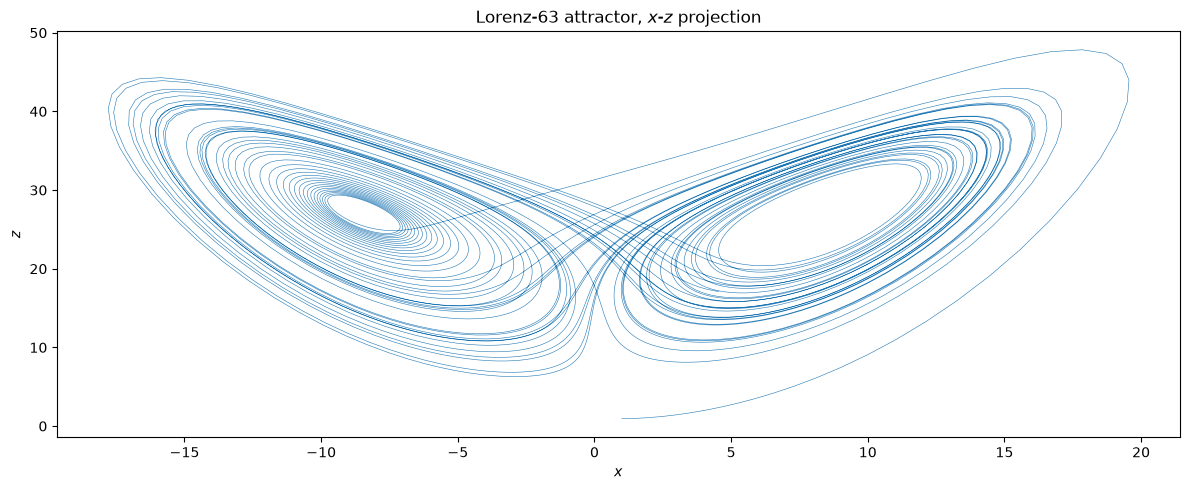

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(attractor.ys.x, attractor.ys.z, color="C0", lw=0.4)
ax.set_xlabel("$x$")
ax.set_ylabel("$z$")
ax.set_title("Lorenz-63 attractor, $x$-$z$ projection")
plt.tight_layout()
plt.show()

The trajectory winds around two lobes and switches between them aperiodically, the signature of low-dimensional chaos.

## 2. Sensitive dependence on initial conditions

Chaos is quantified by the exponential separation of nearby trajectories. Two states that start a tiny distance $\delta_0$ apart diverge, on average, as

$$\delta(t) \sim \delta_0 e^{\lambda t}$$ (p3-lyapunov)

where $\lambda > 0$ is the leading Lyapunov exponent, about $0.9$ for Lorenz-63. The finite growth horizon this implies, not any model deficiency, is the fundamental limit on forecast skill {cite}`lorenz1963deterministic`. We integrate two trajectories whose initial conditions differ by $10^{-6}$ and watch the gap. We use $10^{-6}$ rather than a smaller value because sesmax runs in single precision by default, where perturbations below about $10^{-7}$ vanish into round-off.

In [6]:
# Shapes: N_T = 4,000 saved snapshots

perturbation = 1.0e-6
separation_times = jnp.arange(0.0, 40.0, 0.01)  # → (N_T,)
# today (sesmax_core)
perturbed_state = sxt.L63State(
    x=jnp.array(1.0 + perturbation), y=jnp.array(1.0), z=jnp.array(1.0)
)

# today (sesmax_core, diffrax)
reference_run = lorenz63.integrate(  # x, y, z → (N_T,) each
    initial_state,
    t0=0.0,
    t1=40.0,
    dt=0.01,
    saveat=dfx.SaveAt(ts=separation_times),
    max_steps=20_000,
)
# today (sesmax_core, diffrax)
perturbed_run = lorenz63.integrate(  # x, y, z → (N_T,) each
    perturbed_state,
    t0=0.0,
    t1=40.0,
    dt=0.01,
    saveat=dfx.SaveAt(ts=separation_times),
    max_steps=20_000,
)

# δ(t)² = Δx² + Δy² + Δz²
squared_separation = (  # → (N_T,)
    (reference_run.ys.x - perturbed_run.ys.x) ** 2
    + (reference_run.ys.y - perturbed_run.ys.y) ** 2
    + (reference_run.ys.z - perturbed_run.ys.z) ** 2
)
separation = jnp.sqrt(squared_separation)  # → (N_T,)

print(f"Separation at t = 20: {float(separation[2000]):.2e}")
print(f"Separation at t = 40: {float(separation[-1]):.2f}")

Separation at t = 20: 1.51e-01
Separation at t = 40: 20.48


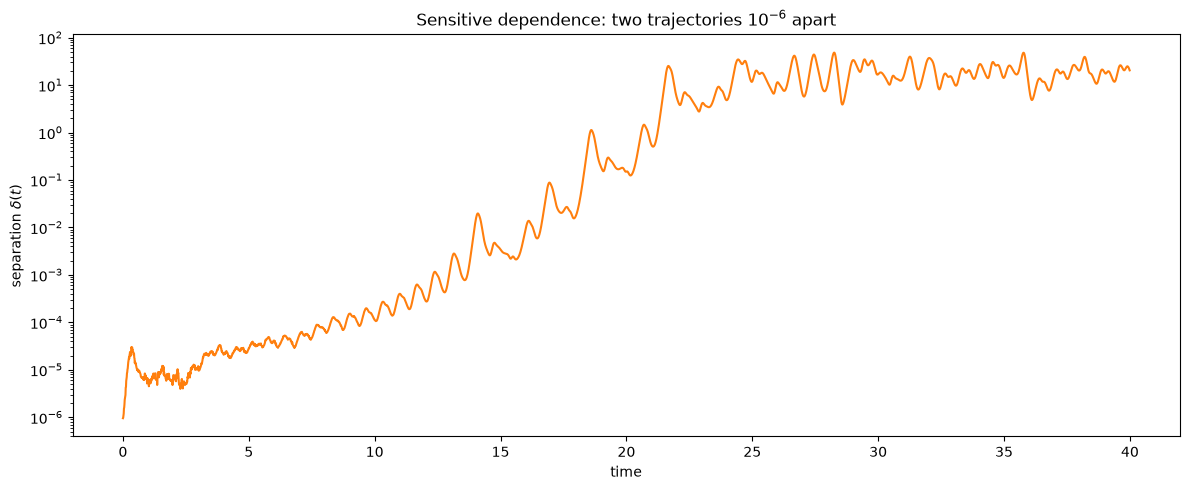

In [7]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.semilogy(separation_times, separation, color="C1")
ax.set_xlabel("time")
ax.set_ylabel(r"separation $\delta(t)$")
ax.set_title("Sensitive dependence: two trajectories $10^{-6}$ apart")
plt.tight_layout()
plt.show()

The ramp on the log axis is the exponential growth of {eq}`p3-lyapunov`. Growth saturates once the gap reaches the size of the attractor itself, at which point the two forecasts are effectively independent.

One pair of trajectories samples only one stretch of the attractor, so its slope is a noisy estimate of $\lambda$, which is a long-time average. To measure the average, we keep a pair close together: run both for a short window $\tau$, record the growth, rescale the gap back to $\delta_0$ along the same direction and repeat, so that

$$\lambda \approx \frac{1}{N_W \tau} \sum_{w=1}^{N_W} \log \frac{\delta_w}{\delta_0}$$ (p3-benettin)

where $\delta_w$ is the gap at the end of window $w$ and $N_W$ is the number of windows.

In [8]:
# Shapes: N_W = 2,000 windows of τ = 0.5; 3 state variables

window_length = 0.5
reference_gap = 1.0e-3
num_windows = 2_000


def advance(state):
    """x(t + τ) from x(t); the system is autonomous, so each window starts at 0."""
    # today (sesmax_core, diffrax)
    window = lorenz63.integrate(state, t0=0.0, t1=window_length, dt=0.01)
    return sxt.L63State(x=window.ys.x[-1], y=window.ys.y[-1], z=window.ys.z[-1])


def rescale_window(pair, _):
    """Advance both trajectories one window and rescale their gap back to δ₀."""
    reference, neighbour = pair
    reference = advance(reference)
    neighbour = advance(neighbour)
    # Δ = x_neighbour − x_reference
    gap_x = neighbour.x - reference.x  # → ()
    gap_y = neighbour.y - reference.y  # → ()
    gap_z = neighbour.z - reference.z  # → ()
    # δ_w = ‖Δ‖₂
    gap = jnp.sqrt(gap_x**2 + gap_y**2 + gap_z**2)  # → ()
    # x_neighbour = x_reference + δ₀ Δ / δ_w
    factor = reference_gap / gap  # → ()
    # today (sesmax_core)
    neighbour = sxt.L63State(
        x=reference.x + factor * gap_x,
        y=reference.y + factor * gap_y,
        z=reference.z + factor * gap_z,
    )
    # log(δ_w / δ₀)
    return (reference, neighbour), jnp.log(gap / reference_gap)


# Start on the attractor, from the end of the run above
# today (sesmax_core)
start = sxt.L63State(x=attractor.ys.x[-1], y=attractor.ys.y[-1], z=attractor.ys.z[-1])
# today (sesmax_core)
neighbour = sxt.L63State(x=start.x + reference_gap, y=start.y, z=start.z)
# today (jax)
_, log_growth = jax.lax.scan(  # → (N_W,)
    rescale_window, (start, neighbour), None, length=num_windows
)
# λ ≈ (1 / (N_W τ)) ∑_w log(δ_w / δ₀)
lyapunov = jnp.sum(log_growth) / (num_windows * window_length)  # → ()
print(f"Leading Lyapunov exponent: {float(lyapunov):.2f}")

Leading Lyapunov exponent: 0.91


## 3. Lorenz-96: spatiotemporal chaos on a ring

Lorenz-96 extends the idea to $D_x$ variables arranged on a periodic ring, each representing an atmospheric quantity at one longitude,

$$\frac{\mathrm{d}x_k}{\mathrm{d}t} = (x_{k+1} - x_{k-2}) x_{k-1} - x_k + F$$ (p3-lorenz96)

with cyclic indices and a constant forcing $F$ {cite}`lorenz1996predictability`. The quadratic term advects, the linear term damps and $F$ injects energy; at $F = 8$ the balance produces travelling waves that break into sustained spatiotemporal chaos. Because it is high-dimensional yet cheap, Lorenz-96 is the standard proving ground for data-assimilation schemes. The [Lorenz '96 page](lorenz96_simulation.ipynb) goes further, and [the two-tier version](lorenz96t_simulation.ipynb) adds fast variables.

In [9]:
# Shapes: D_x = 40 variables; N_T = 2,000 saved snapshots

# today (sesmax_core)
lorenz96 = sxt.Lorenz96.create(F=8.0)
ring_state = sxt.L96State.init_state(ndim=40, noise=0.01, F=8.0)

ring_times = jnp.arange(0.0, 20.0, 0.01)  # → (N_T,)
# today (sesmax_core, diffrax)
ring = lorenz96.integrate(  # x → (N_T, D_x)
    ring_state,
    t0=0.0,
    t1=20.0,
    dt=0.01,
    saveat=dfx.SaveAt(ts=ring_times),
    max_steps=20_000,
)
print(f"Lorenz-96 Hovmoller: {ring.ys.x.shape} (time, longitude)")

Lorenz-96 Hovmoller: (2000, 40) (time, longitude)


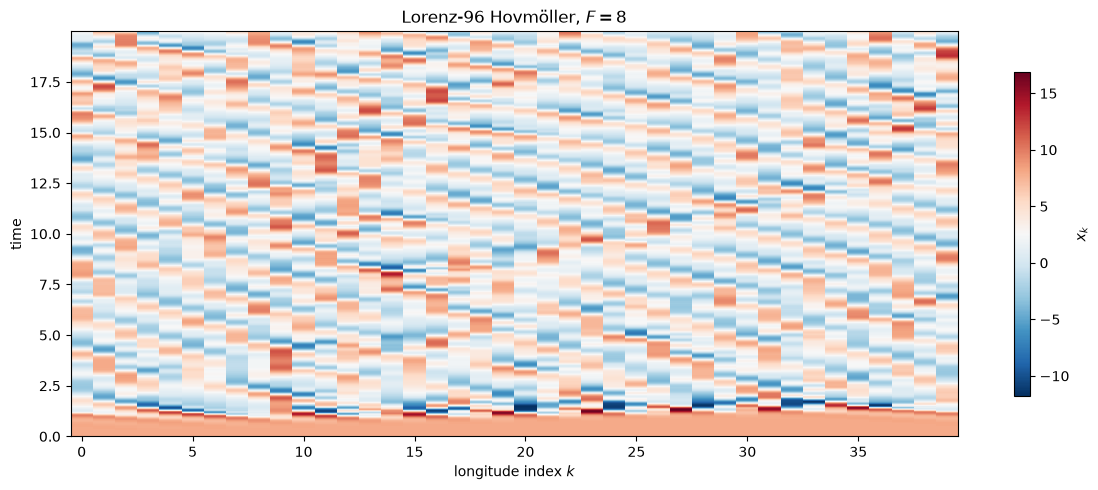

In [10]:
fig, ax = plt.subplots(figsize=(12, 5))
positions = jnp.arange(40)  # → (D_x,)
mesh = ax.pcolormesh(positions, ring_times, ring.ys.x, cmap="RdBu_r", shading="auto")
ax.set_xlabel("longitude index $k$")
ax.set_ylabel("time")
ax.set_title("Lorenz-96 Hovmöller, $F=8$")
plt.colorbar(mesh, ax=ax, shrink=0.8, label="$x_k$")
plt.tight_layout()
plt.show()

This Hovmöller diagram has longitude on the horizontal axis and time on the vertical. The slanted bands are propagating waves, and their irregular merging and splitting is the spatiotemporal chaos that makes the system a low-cost atmosphere surrogate.

## Summary

- Lorenz-63, {eq}`p3-lorenz63-x` to {eq}`p3-lorenz63-z`, traces a bounded strange attractor; the flow is deterministic yet never repeats.
- Sensitive dependence, the exponential separation {eq}`p3-lyapunov` of nearby states at the positive Lyapunov rate, is the intrinsic limit on predictability, not a numerical artefact.
- Lorenz-96 {eq}`p3-lorenz96` lifts chaos onto a ring, giving high-dimensional spatiotemporal chaos at trivial cost, and it is the canonical data-assimilation test bed.

**Next:** [Lorenz '63](lorenz63_simulation.ipynb) works through the first system in detail.